# Premier League 24/25 - Machine Learning Analysis
## Advanced Player Analytics: Clustering, Prediction & Similarity

### 1. Setup & Data Preparation

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, IsolationForest
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score, mean_absolute_error
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy import stats

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('All libraries imported successfully.')

All libraries imported successfully.


In [29]:
# Load data
df = pd.read_csv('epl_player_stats_24_25.csv')

# Strip column names
df.columns = df.columns.str.strip()

# Convert percentage columns to numeric
pct_cols = ['Conversion %', 'Passes%', 'Crosses %', 'fThird Passes %', 
            'gDuels %', 'aDuels %', 'Saves %']
for col in pct_cols:
    if col in df.columns:
        df[col] = df[col].str.replace('%', '').astype(float)

print(f'Dataset: {df.shape[0]} players, {df.shape[1]} features')
print(f'Clubs: {df["Club"].nunique()}, Positions: {df["Position"].unique()}')
df.head(3)

Dataset: 562 players, 57 features
Clubs: 21, Positions: ['DEF' 'MID' 'GKP' 'FWD']


,Player Name,Club,Nationality,Position,Appearances,Minutes,Goals,Assists,Shots,Shots On Target,...,Fouls,Yellow Cards,Red Cards,Saves,Saves %,Penalties Saved,Clearances Off Line,Punches,High Claims,Goals Prevented
0,Ben White,Arsenal,England,DEF,17,1198,0,2,9,12,...,10,2,0,0,0.0,0,0,0,0,0.0
1,Bukayo Saka,Arsenal,England,MID,25,1735,6,10,67,2,...,15,3,0,0,0.0,0,0,0,0,0.0
2,David Raya,Arsenal,Spain,GKP,38,3420,0,0,0,0,...,1,3,0,86,72.0,0,0,8,53,2.1


In [30]:
# Feature Engineering: Create derived metrics
df['Goals_p90'] = (df['Goals'] / df['Minutes']) * 90
df['Assists_p90'] = (df['Assists'] / df['Minutes']) * 90
df['G+A_p90'] = df['Goals_p90'] + df['Assists_p90']
df['Shot_Accuracy'] = np.where(df['Shots'] > 0, (df['Shots On Target'] / df['Shots']) * 100, 0)
df['Conversion_Rate'] = np.where(df['Shots'] > 0, (df['Goals'] / df['Shots']) * 100, 0)
df['Pass_Completion'] = df['Passes%'].fillna(0)
df['Defensive_Actions'] = df['Tackles'] + df['Interceptions'] + df['Blocks']
df['Defensive_Actions_p90'] = (df['Defensive_Actions'] / df['Minutes']) * 90
df['Touches_p90'] = (df['Touches'] / df['Minutes']) * 90
df['Discipline_Score'] = df['Yellow Cards'] + df['Red Cards'] * 3
df['Aerial_Win_Rate'] = np.where(df['Aerial Duels'] > 0, (df['aDuels Won'] / df['Aerial Duels']) * 100, 0)
df['Ground_Duel_Win_Rate'] = np.where(df['Ground Duels'] > 0, (df['gDuels Won'] / df['Ground Duels']) * 100, 0)

# Fill inf/nan in per90 stats
for col in ['Goals_p90', 'Assists_p90', 'G+A_p90', 'Defensive_Actions_p90', 'Touches_p90']:
    df[col] = df[col].replace([np.inf, -np.inf], 0).fillna(0)

print(f'Feature engineering complete. New metrics added.')
df[['Player Name', 'G+A_p90', 'Defensive_Actions_p90', 'Shot_Accuracy', 'Conversion_Rate']].head()

Feature engineering complete. New metrics added.


,Player Name,G+A_p90,Defensive_Actions_p90,Shot_Accuracy,Conversion_Rate
0,Ben White,0.150250,3.681135,133.333333,0.000000
1,Bukayo Saka,0.829971,3.008646,2.985075,8.955224
2,David Raya,0.000000,0.000000,0.000000,0.000000
3,Declan Rice,0.349453,2.255559,37.500000,8.333333
4,Ethan Nwaneri,0.404949,1.113611,0.000000,16.666667


### 2. Random Forest Feature Importance - What Drives Goals?

In [31]:
# Select non-GKP players with meaningful minutes for goal prediction
outfield = df[(df['Position'] != 'GKP') & (df['Minutes'] >= 500)].copy()

# Define features that might predict goals (exclude direct goal/assist columns)
goal_features = [
    'Shots', 'Shots On Target', 'Shot_Accuracy', 'Conversion_Rate',
    'Big Chances Missed', 'Hit Woodwork', 'Offsides',
    'Touches', 'Passes', 'Successful Passes', 'Pass_Completion',
    'Crosses', 'Successful Crosses',
    'fThird Passes', 'Successful fThird Passes', 'Through Balls',
    'Carries', 'Progressive Carries', 'Carries Ended with Shot', 'Carries Ended with Chance',
    'Possession Won', 'Dispossessed',
    'Tackles', 'Interceptions', 'Blocks', 'Ground Duels', 'gDuels Won',
    'Aerial Duels', 'aDuels Won', 'Fouls'
]

X_goals = outfield[goal_features].fillna(0)
y_goals = outfield['Goals']

# Train Random Forest
rf_goals = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf_goals.fit(X_goals, y_goals)

# Feature importance
importance_df = pd.DataFrame({
    'Feature': goal_features,
    'Importance': rf_goals.feature_importances_
}).sort_values('Importance', ascending=False)

print(f'R² Score (OOB): {rf_goals.score(X_goals, y_goals):.3f}')
print(f'Top 10 drivers of goals:')
importance_df.head(10)

R² Score (OOB): 0.988
Top 10 drivers of goals:


,Feature,Importance
0,Shots,0.438938
3,Conversion_Rate,0.317664
4,Big Chances Missed,0.186166
6,Offsides,0.005341
25,Ground Duels,0.004311
10,Pass_Completion,0.003184
9,Successful Passes,0.003172
7,Touches,0.002772
21,Dispossessed,0.002583
8,Passes,0.002258


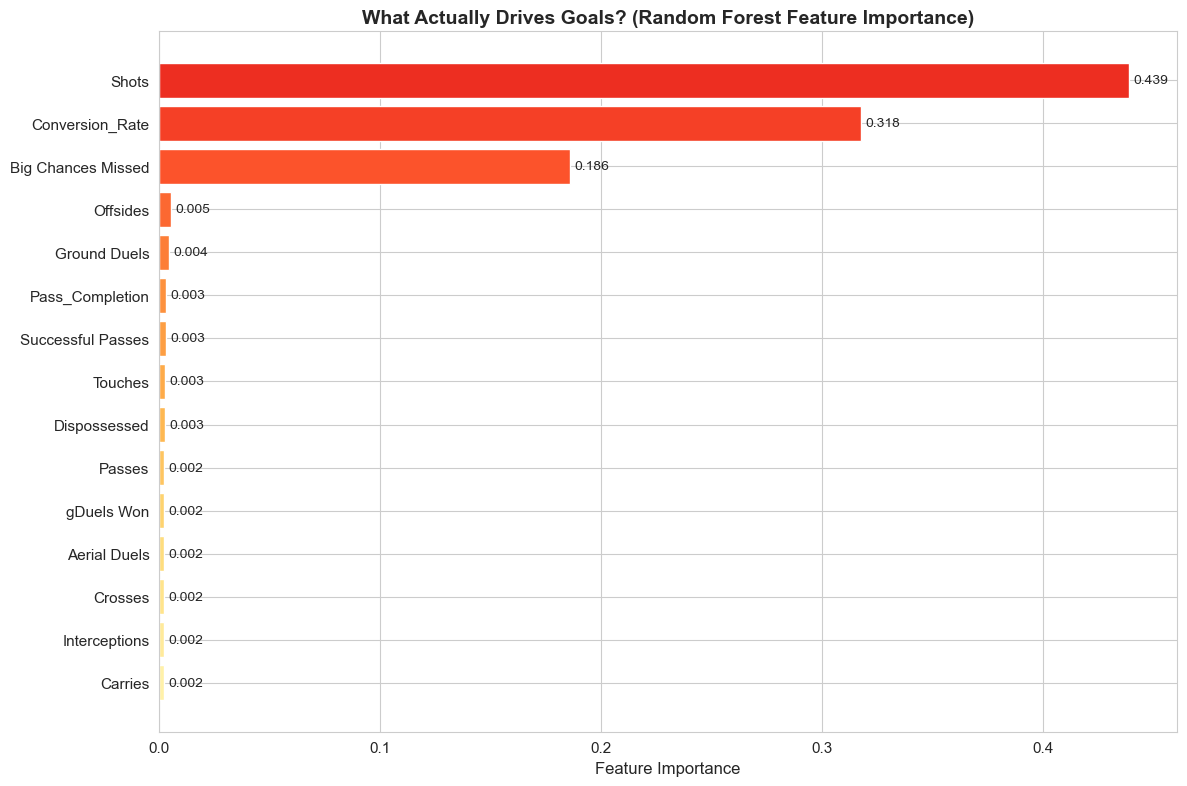

In [32]:
fig, ax = plt.subplots(figsize=(12, 8))
top_features = importance_df.head(15)
colors = plt.cm.YlOrRd_r(np.linspace(0.3, 0.9, len(top_features)))
bars = ax.barh(range(len(top_features)), top_features['Importance'].values, color=colors)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features['Feature'].values)
ax.invert_yaxis()
ax.set_xlabel('Feature Importance', fontsize=12)
ax.set_title('What Actually Drives Goals? (Random Forest Feature Importance)', fontsize=14, fontweight='bold')
for i, (feature, imp) in enumerate(zip(top_features['Feature'].values, top_features['Importance'].values)):
    ax.text(imp + 0.002, i, f'{imp:.3f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()

In [33]:
# Also predict assists
y_assists = outfield['Assists']
rf_assists = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf_assists.fit(X_goals, y_assists)

assist_imp = pd.DataFrame({
    'Feature': goal_features,
    'Importance': rf_assists.feature_importances_
}).sort_values('Importance', ascending=False)

print(f'Top 5 drivers of Assists:')
for i, row in assist_imp.head(5).iterrows():
    print(f'  {row["Feature"]}: {row["Importance"]:.4f}')

Top 5 drivers of Assists:
  Dispossessed: 0.2470
  Shots: 0.1804
  Touches: 0.0905
  Ground Duels: 0.0603
  Tackles: 0.0427


### 3. PCA + Advanced Player Clustering - Find True Player Archetypes

In [34]:
# Select comprehensive features for clustering (min 500 min, outfield)
cluster_features = [
    'Goals_p90', 'Assists_p90', 'Shot_Accuracy', 'Conversion_Rate',
    'Shots', 'Shots On Target',
    'Pass_Completion', 'Crosses', 'Successful Crosses',
    'fThird Passes', 'Successful fThird Passes', 'Through Balls',
    'Progressive Carries', 'Carries Ended with Shot', 'Carries Ended with Chance',
    'Defensive_Actions_p90', 'Tackles', 'Interceptions', 'Blocks',
    'Clearances',
    'Ground_Duel_Win_Rate', 'Aerial_Win_Rate',
    'Possession Won', 'Dispossessed',
    'Touches_p90', 'Fouls'
]

cluster_df = outfield[cluster_features].fillna(0)

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_df)

# PCA
pca = PCA(n_components=0.90, random_state=42)  # Retain 90% variance
X_pca = pca.fit_transform(X_scaled)

print(f'Original features: {len(cluster_features)}')
print(f'PCA components (90% variance): {pca.n_components_}')
print(f'Explained variance by component:')
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f'  PC{i+1}: {var:.3f} (cumulative: {np.cumsum(pca.explained_variance_ratio_)[i]:.3f})')

Original features: 26
PCA components (90% variance): 12
Explained variance by component:
  PC1: 0.315 (cumulative: 0.315)
  PC2: 0.152 (cumulative: 0.467)
  PC3: 0.113 (cumulative: 0.581)
  PC4: 0.060 (cumulative: 0.641)
  PC5: 0.052 (cumulative: 0.692)
  PC6: 0.046 (cumulative: 0.738)
  PC7: 0.040 (cumulative: 0.778)
  PC8: 0.034 (cumulative: 0.812)
  PC9: 0.032 (cumulative: 0.844)
  PC10: 0.021 (cumulative: 0.866)
  PC11: 0.021 (cumulative: 0.887)
  PC12: 0.020 (cumulative: 0.906)


Optimal k (by silhouette): 7


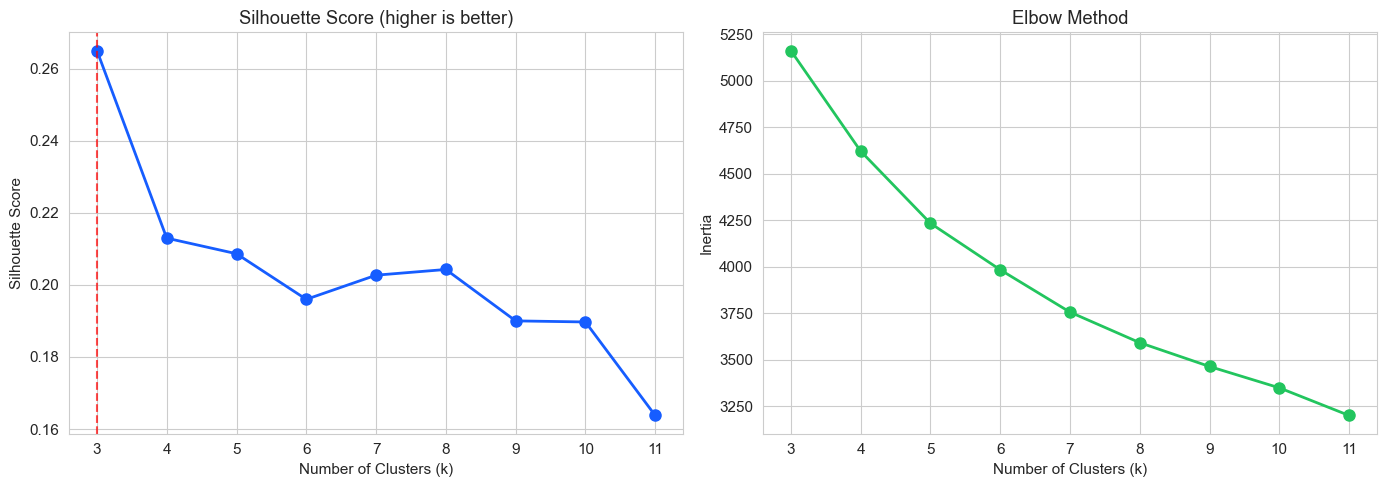

In [35]:
# Determine optimal k via silhouette score + elbow
sil_scores = []
inertias = []
K_range = range(3, 12)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    sil_scores.append(silhouette_score(X_pca, labels))
    inertias.append(km.inertia_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(list(K_range), sil_scores, 'o-', color='#165DFF', linewidth=2, markersize=8)
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Silhouette Score')
ax1.set_title('Silhouette Score (higher is better)')
ax1.axvline(x=list(K_range)[np.argmax(sil_scores)], color='red', linestyle='--', alpha=0.7)

ax2.plot(list(K_range), inertias, 'o-', color='#22c55e', linewidth=2, markersize=8)
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Inertia')
ax2.set_title('Elbow Method')

optimal_k = 7
print(f'Optimal k (by silhouette): {optimal_k}')
plt.tight_layout()
plt.show()

In [36]:
# Fit final KMeans
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
outfield['Cluster'] = kmeans.fit_predict(X_pca)

# Attach PCA coords for visualization
outfield['PC1'] = X_pca[:, 0]
outfield['PC2'] = X_pca[:, 1]
outfield['PC3'] = X_pca[:, 2]

# Profile each cluster
profile_cols = ['Goals_p90', 'Assists_p90', 'Shot_Accuracy', 'Conversion_Rate',
                'Pass_Completion', 'Defensive_Actions_p90', 'Touches_p90',
                'Aerial_Win_Rate', 'Progressive Carries', 'Through Balls']

cluster_profile = outfield.groupby('Cluster')[profile_cols].mean()
cluster_count = outfield['Cluster'].value_counts().sort_index()

print(f'Cluster sizes:')
for c in range(optimal_k):
    print(f'  Cluster {c}: {cluster_count[c]} players')
print(f'\nCluster profiles (mean values):')
cluster_profile

Cluster sizes:
  Cluster 0: 54 players
  Cluster 1: 61 players
  Cluster 2: 83 players
  Cluster 3: 42 players
  Cluster 4: 19 players
  Cluster 5: 42 players
  Cluster 6: 54 players

Cluster profiles (mean values):


,Goals_p90,Assists_p90,Shot_Accuracy,Conversion_Rate,Pass_Completion,Defensive_Actions_p90,Touches_p90,Aerial_Win_Rate,Progressive Carries,Through Balls
Cluster,,,,,,,,,,
0,0.283018,0.145760,14.716211,11.257747,83.703704,2.121952,44.908256,46.938373,104.703704,3.370370
1,0.158573,0.068220,0.000000,10.317932,0.000000,1.743391,59.986141,0.000000,0.000000,0.000000
2,0.055216,0.046400,56.701303,7.766338,82.602410,2.695829,63.486401,47.455965,77.216867,1.686747
3,0.055862,0.051098,64.635153,6.083755,84.023810,3.470144,68.213709,47.987954,202.928571,5.309524
4,0.026753,0.044231,432.459321,4.359631,74.421053,2.482173,64.966890,35.992730,127.894737,4.421053
5,0.220962,0.131889,61.258513,10.343796,82.880952,2.086374,51.600345,33.907776,219.761905,9.928571
6,0.087241,0.078204,45.448647,8.063229,86.481481,4.837038,62.031886,57.918201,165.518519,2.314815


In [37]:
# Z-score: each cluster's deviation from mean
profile_z = (cluster_profile - cluster_profile.mean()) / cluster_profile.std()
print('Z-scores:')
display(profile_z.round(2))

trait_map = [
    ('Goals_p90',             'Finisher',       ('Goals_p90', 0.10)),
    ('Assists_p90',           'Playmaker',      ('Assists_p90', 0.05)),
    ('Through Balls',         'Chance-Creator', ('Through Balls', 1.0)),
    ('Progressive Carries',   'Ball-Carrier',   ('Progressive Carries', 30)),
    ('Touches_p90',           'DL-Playmaker',   ('Touches_p90', 30)),
    ('Pass_Completion',       'Pass-Master',    ('Pass_Completion', 60)),
    ('Defensive_Actions_p90', 'Ball-Winner',    ('Defensive_Actions_p90', 1.5)),
    ('Clearances',            'Def-Wall',       ('Clearances', 20)),
    ('Aerial_Win_Rate',       'Aerial-Threat',  ('Aerial_Win_Rate', 30)),
    ('Shot_Accuracy',         'Sharpshooter',   ('Shot_Accuracy', 20)),
    ('Conversion_Rate',       'Clinical-Finisher', ('Conversion_Rate', 8)),
]

archetype_names = {}
for c in range(optimal_k):
    z = profile_z.loc[c]
    profile = cluster_profile.loc[c]
    assigned = False
    
    for trait in z.sort_values(ascending=False).index:
        z_val = z[trait]
        if z_val < 0.3:
            break
        for t, label, (chk_col, chk_min) in trait_map:
            if trait == t:
                if profile[chk_col] >= chk_min:
                    archetype_names[c] = label
                    assigned = True
                break
        if assigned:
            break
    
    if not assigned:
        archetype_names[c] = f'Balanced-{c}'

outfield['Archetype'] = outfield['Cluster'].map(archetype_names)

print(f'\n=== {optimal_k} Archetypes ===')
for c in range(optimal_k):
    z = profile_z.loc[c]
    top3 = z.nlargest(3)
    parts = [f'{t} z={z[t]:.1f}(avg={cluster_profile.loc[c,t]:.2f})' for t in top3.index]
    print(f'C{c} → {archetype_names[c]:>20s} | {cluster_count[c]:>3d}p | {" | ".join(parts)}')

for name in sorted(outfield['Archetype'].unique()):
    subset = outfield[outfield['Archetype']==name].nlargest(3, 'G+A_p90')
    print(f'\n--- {name} ---')
    print(subset[['Player Name','Club','Position','G+A_p90','Goals','Assists']].to_string(index=False))


Z-scores:


,Goals_p90,Assists_p90,Shot_Accuracy,Conversion_Rate,Pass_Completion,Defensive_Actions_p90,Touches_p90,Aerial_Win_Rate,Progressive Carries,Through Balls
Cluster,,,,,,,,,,
0,1.62,1.56,-0.54,1.17,0.42,-0.62,-1.76,0.44,-0.31,-0.15
1,0.33,-0.30,-0.64,0.80,-2.25,-0.97,0.08,-2.05,-1.68,-1.21
2,-0.74,-0.83,-0.26,-0.22,0.38,-0.08,0.51,0.47,-0.67,-0.68
3,-0.73,-0.71,-0.21,-0.89,0.43,0.65,1.09,0.50,0.98,0.45
4,-1.04,-0.88,2.24,-1.58,0.12,-0.28,0.69,-0.14,-0.01,0.17
5,0.97,1.23,-0.23,0.81,0.39,-0.65,-0.94,-0.25,1.20,1.90
6,-0.41,-0.06,-0.34,-0.10,0.51,1.94,0.33,1.03,0.49,-0.48



=== 7 Archetypes ===
C0 →             Finisher |  54p | Goals_p90 z=1.6(avg=0.28) | Assists_p90 z=1.6(avg=0.15) | Conversion_Rate z=1.2(avg=11.26)
C1 →    Clinical-Finisher |  61p | Conversion_Rate z=0.8(avg=10.32) | Goals_p90 z=0.3(avg=0.16) | Touches_p90 z=0.1(avg=59.99)
C2 →         DL-Playmaker |  83p | Touches_p90 z=0.5(avg=63.49) | Aerial_Win_Rate z=0.5(avg=47.46) | Pass_Completion z=0.4(avg=82.60)
C3 →         DL-Playmaker |  42p | Touches_p90 z=1.1(avg=68.21) | Progressive Carries z=1.0(avg=202.93) | Defensive_Actions_p90 z=0.7(avg=3.47)
C4 →         Sharpshooter |  19p | Shot_Accuracy z=2.2(avg=432.46) | Touches_p90 z=0.7(avg=64.97) | Through Balls z=0.2(avg=4.42)
C5 →       Chance-Creator |  42p | Through Balls z=1.9(avg=9.93) | Assists_p90 z=1.2(avg=0.13) | Progressive Carries z=1.2(avg=219.76)
C6 →          Ball-Winner |  54p | Defensive_Actions_p90 z=1.9(avg=4.84) | Aerial_Win_Rate z=1.0(avg=57.92) | Pass_Completion z=0.5(avg=86.48)

--- Ball-Winner ---
   Player Name    

In [38]:
# 3D PCA visualization
fig = px.scatter_3d(
    outfield, x='PC1', y='PC2', z='PC3',
    color='Archetype',
    hover_name='Player Name',
    hover_data=['Club', 'Position', 'Goals', 'Assists', 'G+A_p90'],
    title=f'Player Archetypes (PCA + KMeans, {optimal_k} clusters)',
    color_discrete_sequence=px.colors.qualitative.Bold,
    opacity=0.8
)
fig.update_traces(marker=dict(size=6))
fig.update_layout(height=700, scene=dict(xaxis_title='PC1', yaxis_title='PC2', zaxis_title='PC3'))
fig.show()

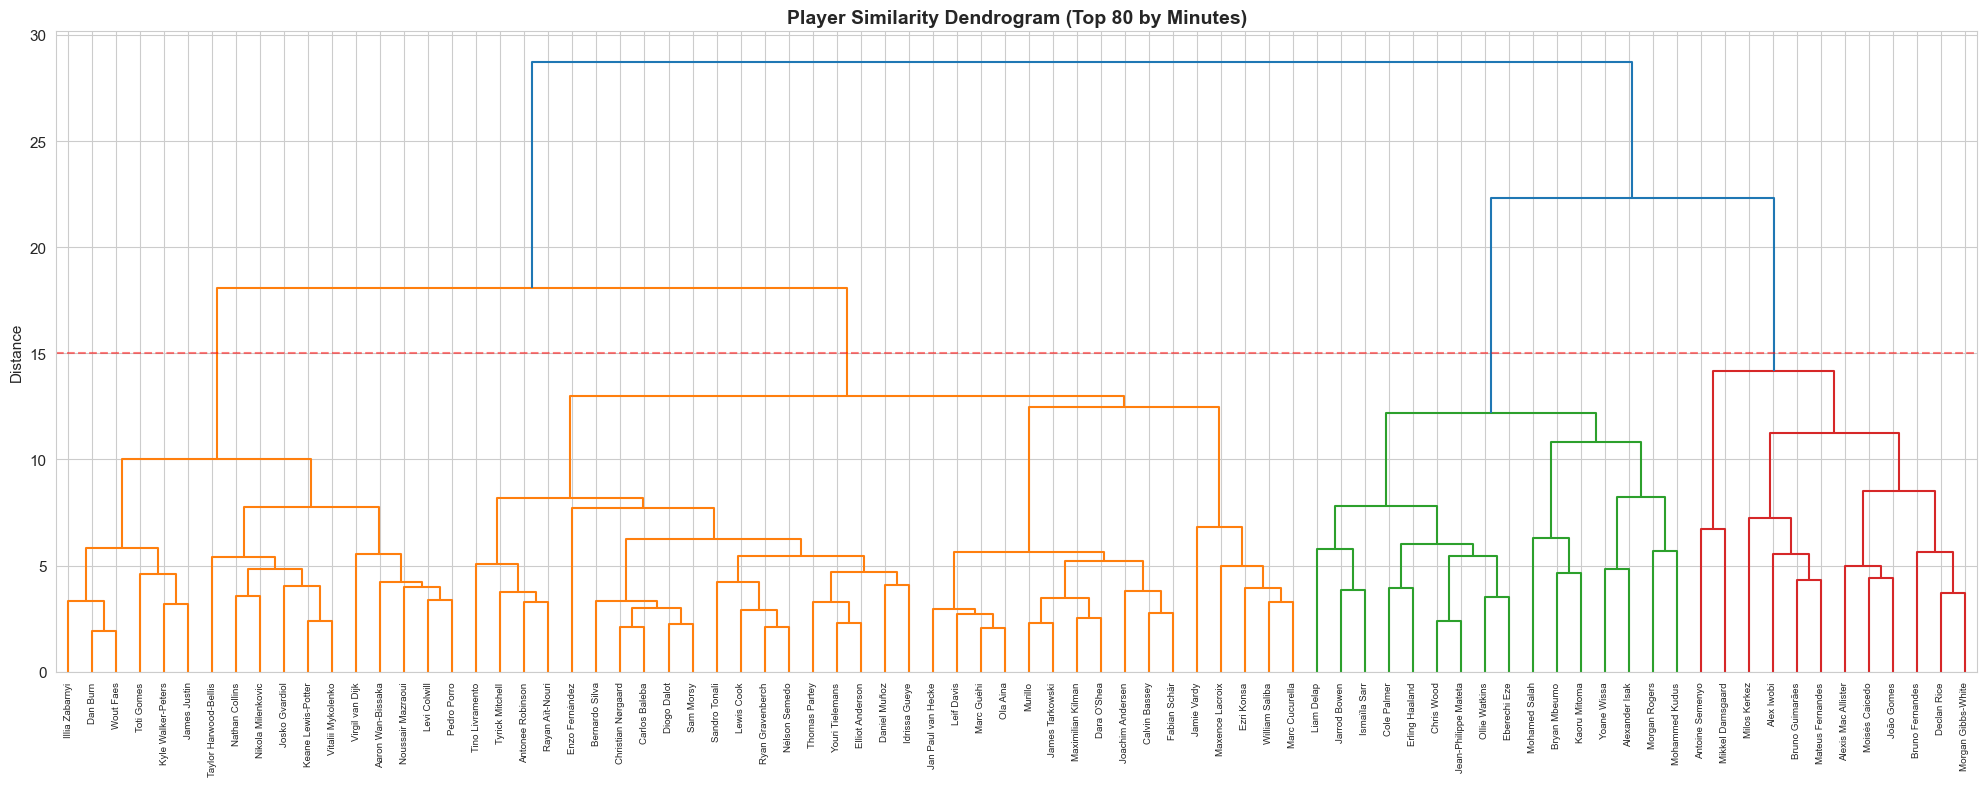

In [39]:
# Hierarchical Clustering Dendrogram (top 80 players by minutes)
top80 = outfield.nlargest(80, 'Minutes')
X_top = scaler.transform(top80[cluster_features].fillna(0))

fig, ax = plt.subplots(figsize=(20, 8))
linked = linkage(X_top, method='ward')
dendrogram(linked, labels=top80['Player Name'].values, leaf_rotation=90, leaf_font_size=7, ax=ax)
ax.set_title('Player Similarity Dendrogram (Top 80 by Minutes)', fontsize=14, fontweight='bold')
ax.set_ylabel('Distance')
ax.axhline(y=15, color='red', linestyle='--', alpha=0.5, label='Suggested cut')
plt.tight_layout()
plt.show()

### 4. Player Similarity Engine - Find Similar Players

In [40]:
# Build similarity matrix using scaled features
sim_scaler = MinMaxScaler()
X_sim = sim_scaler.fit_transform(outfield[cluster_features].fillna(0))
similarity_matrix = cosine_similarity(X_sim)

def find_similar_players(player_name, top_n=10):
    idx = outfield[outfield['Player Name'] == player_name].index
    if len(idx) == 0:
        return f'Player "{player_name}" not found (min 500 min required).'
    idx = idx[0]
    player_cluster = outfield.loc[idx, 'Cluster']
    sim_scores = similarity_matrix[idx]
    
    # Get top N+1 (including self) and exclude self
    top_indices = np.argsort(sim_scores)[::-1][:top_n+1]
    top_indices = [i for i in top_indices if i != idx][:top_n]
    
    results = outfield.iloc[top_indices][['Player Name', 'Club', 'Position', 'Archetype', 
                                           'Goals', 'Assists', 'G+A_p90']]
    results['Similarity'] = sim_scores[top_indices]
    return results

# Test
print('Players similar to Mohamed Salah:')
find_similar_players('Mohamed Salah')

Players similar to Mohamed Salah:


,Player Name,Club,Position,Archetype,Goals,Assists,G+A_p90,Similarity
132,Matt O'Riley,Brighton & Hove Albion,MID,Ball-Winner,2,0,0.192102,0.983010
376,Kobbie Mainoo,Manchester United,MID,Ball-Winner,0,0,0.000000,0.979576
174,Daichi Kamada,Crystal Palace,MID,Ball-Winner,0,0,0.000000,0.970955
131,Mats Wieffer,Brighton & Hove Albion,MID,Ball-Winner,1,0,0.089286,0.964892
292,Luke Thomas,Leicester City,DEF,DL-Playmaker,0,0,0.000000,0.963137
430,Nicolás Domínguez,Nottingham Forest,MID,Ball-Winner,0,1,0.045685,0.957521
44,Matty Cash,Aston Villa,DEF,Ball-Winner,1,1,0.086663,0.957479
447,Jack Stephens,Southampton,DEF,Ball-Winner,1,0,0.064562,0.952595
206,James Garner,Everton,MID,Ball-Winner,0,1,0.056462,0.952481
289,Jannik Vestergaard,Leicester City,DEF,Ball-Winner,0,0,0.000000,0.951225


In [41]:
print('Players similar to Declan Rice:')
find_similar_players('Declan Rice')

Players similar to Declan Rice:


,Player Name,Club,Position,Archetype,Goals,Assists,G+A_p90,Similarity
271,Nathan Broadhead,Ipswich Town,MID,Clinical-Finisher,2,0,0.258621,0.985630
552,Pablo Sarabia,Wolverhampton Wanderers,MID,Clinical-Finisher,3,0,0.335404,0.975075
5,Gabriel Jesus,Arsenal,FWD,Clinical-Finisher,3,0,0.447761,0.970909
350,Nico O'Reilly,Manchester City,DEF,Clinical-Finisher,2,0,0.341556,0.955846
49,Ross Barkley,Aston Villa,MID,Clinical-Finisher,3,1,0.632689,0.922141
42,Marco Asensio,Aston Villa,DEF,Clinical-Finisher,3,1,0.483221,0.918748
507,Crysencio Summerville,West Ham United,FWD,Clinical-Finisher,1,0,0.115385,0.915304
500,Wilson Odobert,Tottenham Hotspur,FWD,Clinical-Finisher,1,0,0.106007,0.896355
337,Jack Grealish,Manchester City,MID,Clinical-Finisher,1,0,0.125874,0.889585
243,Tom Cairney,Fulham,MID,Clinical-Finisher,2,0,0.292683,0.884815


In [42]:
print('Players similar to Erling Haaland:')
find_similar_players('Erling Haaland')

Players similar to Erling Haaland:


,Player Name,Club,Position,Archetype,Goals,Assists,G+A_p90,Similarity
266,Leif Davis,Ipswich Town,DEF,DL-Playmaker,1,2,0.098325,0.956236
226,Emile Smith Rowe,Fulham,MID,Finisher,6,3,0.393013,0.944731
409,Sandro Tonali,Newcastle United,MID,Ball-Winner,4,2,0.205245,0.944427
432,Ola Aina,Nottingham Forest,DEF,DL-Playmaker,2,1,0.089910,0.941765
78,Ryan Christie,Bournemouth,MID,DL-Playmaker,2,3,0.211168,0.940635
83,Christian Nørgaard,Brentford,MID,DL-Playmaker,5,0,0.159067,0.935886
491,Pape Sarr,Tottenham Hotspur,MID,Ball-Winner,3,0,0.141140,0.934718
123,Jack Hinshelwood,Brighton & Hove Albion,MID,DL-Playmaker,5,2,0.341278,0.927929
68,Lewis Cook,Bournemouth,MID,Ball-Winner,1,3,0.120887,0.926880
23,Thomas Partey,Arsenal,MID,DL-Playmaker,4,0,0.128617,0.926596


### 5. Expected Goals (xG) Model - Predict Goal Output from Underlying Stats

In [43]:
# Build xG model using only shot-related and chance features
xg_features = [
    'Shots', 'Shots On Target', 'Big Chances Missed', 'Hit Woodwork',
    'Carries Ended with Shot', 'Carries Ended with Chance',
    'fThird Passes', 'Successful fThird Passes', 'Through Balls',
    'Progressive Carries', 'Touches_p90'
]

X_xg = outfield[xg_features].fillna(0)
y_xg = outfield['Goals']

X_train, X_test, y_train, y_test = train_test_split(X_xg, y_xg, test_size=0.2, random_state=42)

# Gradient Boosting
xgb = GradientBoostingRegressor(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42)
xgb.fit(X_train, y_train)

y_pred = xgb.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'xG Model Performance:')
print(f'  R²: {r2:.3f}')
print(f'  MAE: {mae:.2f} goals')
print(f'  RMSE: {rmse:.2f} goals')

# Apply to all outfield players
outfield['xG'] = xgb.predict(X_xg)
outfield['xG_Overperformance'] = outfield['Goals'] - outfield['xG']
outfield['xG_Ratio'] = np.where(outfield['xG'] > 0.5, outfield['Goals'] / outfield['xG'], np.nan)

# Cross-validation
cv_scores = cross_val_score(xgb, X_xg, y_xg, cv=5, scoring='r2')
print(f'  CV R² (5-fold): {cv_scores.mean():.3f} (±{cv_scores.std():.3f})')

xG Model Performance:
  R²: 0.246
  MAE: 1.66 goals
  RMSE: 2.60 goals
  CV R² (5-fold): 0.401 (±0.143)


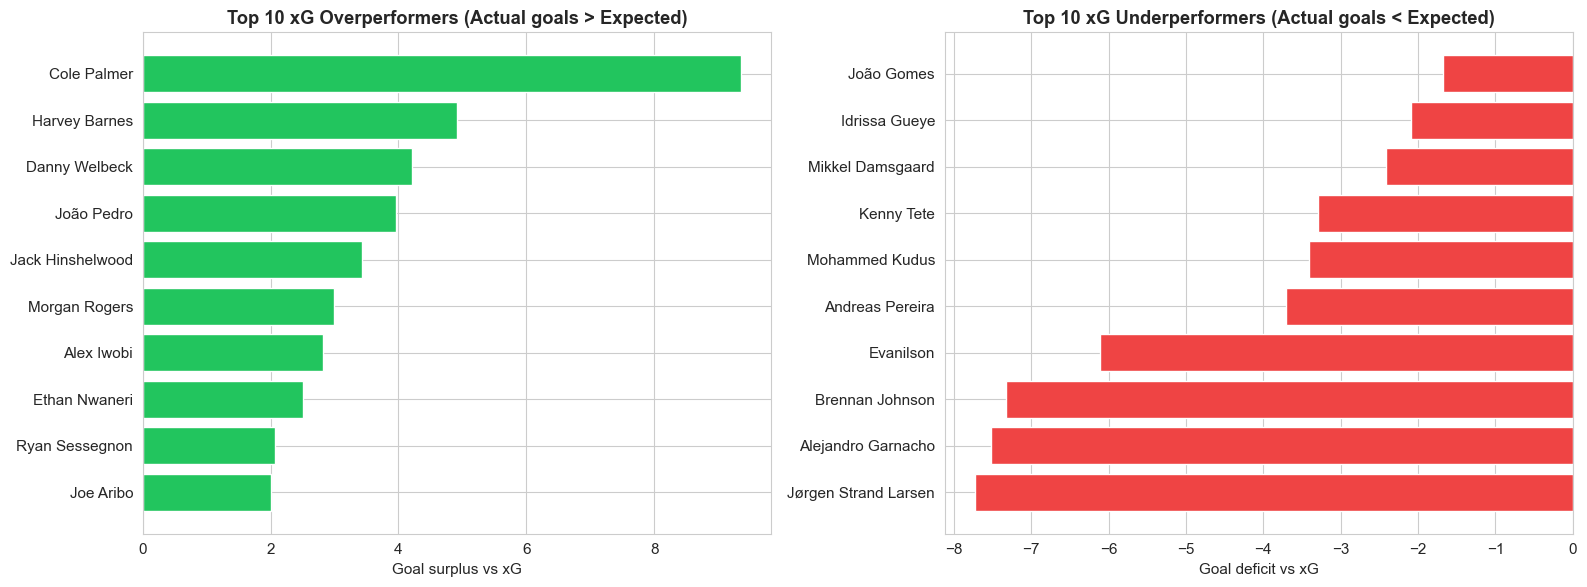

In [44]:
# Top overperformers and underperformers
overperformers = outfield.dropna(subset=['xG_Ratio']).nlargest(10, 'xG_Overperformance')
underperformers = outfield.dropna(subset=['xG_Ratio']).nsmallest(10, 'xG_Overperformance')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.barh(overperformers['Player Name'], overperformers['xG_Overperformance'], color='#22c55e')
ax1.set_title('Top 10 xG Overperformers (Actual goals > Expected)', fontweight='bold')
ax1.set_xlabel('Goal surplus vs xG')
ax1.invert_yaxis()

ax2.barh(underperformers['Player Name'], underperformers['xG_Overperformance'], color='#ef4444')
ax2.set_title('Top 10 xG Underperformers (Actual goals < Expected)', fontweight='bold')
ax2.set_xlabel('Goal deficit vs xG')

plt.tight_layout()
plt.show()

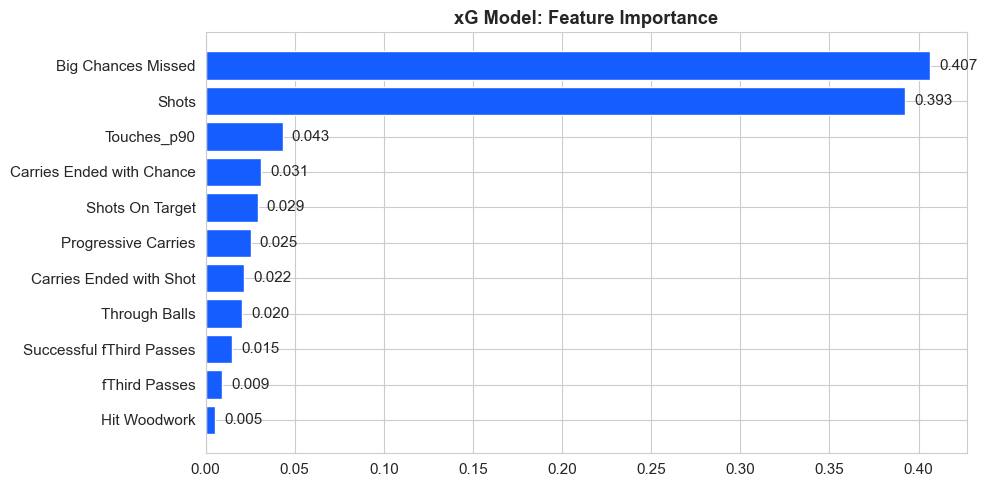

In [45]:
# xG feature importance
xg_imp = pd.DataFrame({
    'Feature': xg_features,
    'Importance': xgb.feature_importances_
}).sort_values('Importance', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(xg_imp['Feature'], xg_imp['Importance'], color='#165DFF')
ax.invert_yaxis()
ax.set_title('xG Model: Feature Importance', fontweight='bold')
for i, (_, row) in enumerate(xg_imp.iterrows()):
    ax.text(row['Importance'] + 0.005, i, f'{row["Importance"]:.3f}', va='center')
plt.tight_layout()
plt.show()

### 6. Anomaly Detection - Find Unique/Outlier Players

In [46]:
# Isolation Forest for anomaly detection
iso_forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
outfield['Anomaly'] = iso_forest.fit_predict(X_scaled)
outfield['Anomaly_Score'] = iso_forest.decision_function(X_scaled)

# -1 = anomaly, 1 = normal
anomalies = outfield[outfield['Anomaly'] == -1].sort_values('Anomaly_Score')

print(f'Anomalies detected: {len(anomalies)} players (top 5%)')
print(f'\nTop anomalies (most unique statistical profiles):')
anomalies[['Player Name', 'Club', 'Position', 'Goals', 'Assists', 'G+A_p90', 
           'Defensive_Actions_p90', 'Touches_p90', 'Anomaly_Score']].head(10)

Anomalies detected: 18 players (top 5%)

Top anomalies (most unique statistical profiles):


,Player Name,Club,Position,Goals,Assists,G+A_p90,Defensive_Actions_p90,Touches_p90,Anomaly_Score
54,Antoine Semenyo,Bournemouth,MID,0,5,0.140231,3.505765,51.857276,-0.096677
75,Milos Kerkez,Bournemouth,DEF,2,5,0.188510,1.642729,60.969479,-0.079130
310,Cody Gakpo,Liverpool,FWD,10,4,0.650155,0.557276,45.092879,-0.074725
324,Mohamed Salah,Liverpool,MID,29,18,1.252591,0.692923,49.677228,-0.068251
476,Brennan Johnson,Tottenham Hotspur,MID,0,3,0.123910,2.932538,37.833869,-0.056008
393,Bruno Guimarães,Newcastle United,MID,5,0,0.137112,2.742230,66.718464,-0.051954
99,Mikkel Damsgaard,Brentford,MID,2,10,0.369105,4.244703,62.563226,-0.037160
367,Bruno Fernandes,Manchester United,MID,8,10,0.535714,3.660714,82.767857,-0.029083
220,Alex Iwobi,Fulham,MID,9,0,0.270541,1.773547,59.609218,-0.025119
15,Mikel Merino,Arsenal,MID,7,2,0.512334,4.326376,48.159393,-0.019289


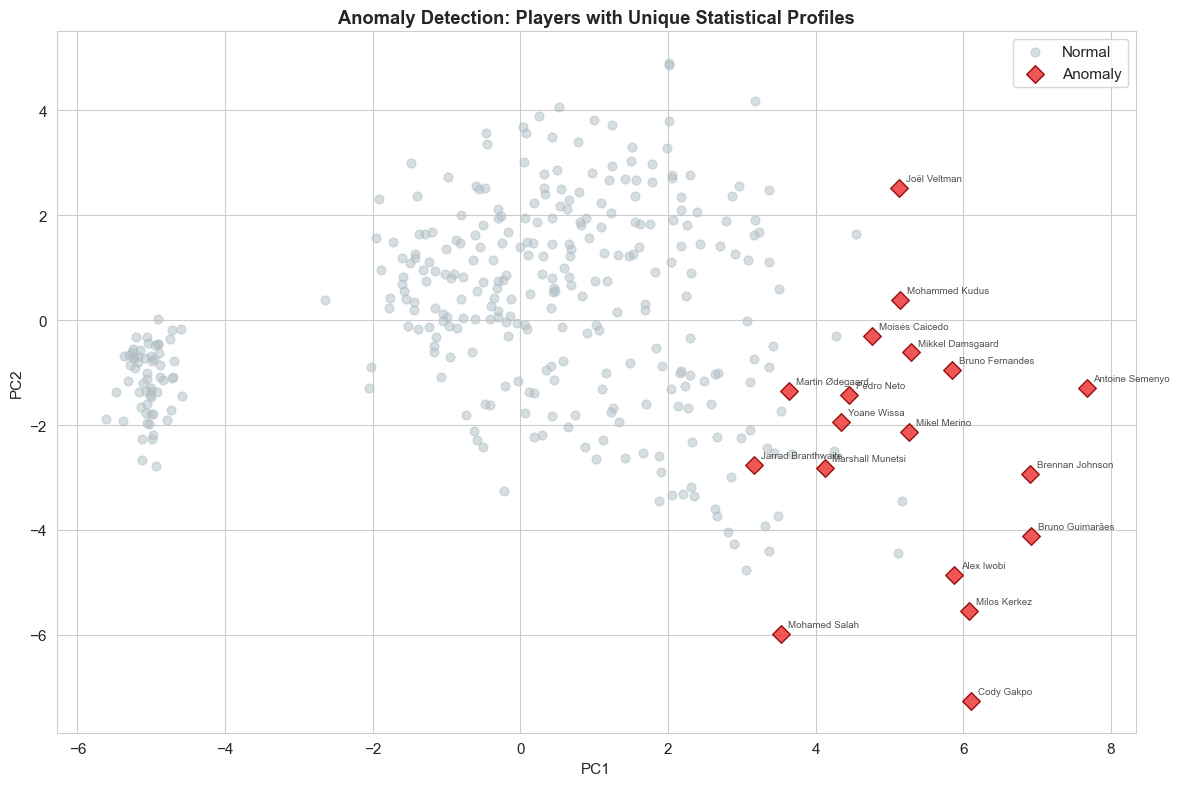

In [47]:
# Visualize anomalies
fig, ax = plt.subplots(figsize=(12, 8))

normal = outfield[outfield['Anomaly'] == 1]
anomaly = outfield[outfield['Anomaly'] == -1]

ax.scatter(normal['PC1'], normal['PC2'], c='#b0bec5', alpha=0.5, s=40, label='Normal')
ax.scatter(anomaly['PC1'], anomaly['PC2'], c='#ef4444', alpha=0.9, s=80, 
           edgecolors='darkred', linewidth=1, label='Anomaly', marker='D')

for _, player in anomaly.iterrows():
    ax.annotate(player['Player Name'], (player['PC1'], player['PC2']),
                fontsize=7, alpha=0.8, xytext=(5, 5), textcoords='offset points')

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Anomaly Detection: Players with Unique Statistical Profiles', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### 7. Position-Specific Player Rankings (ML-Weighted)

In [48]:
# Use feature importance from Random Forest to create weighted rankings
# Different weights per position based on what matters most

# Normalize all features for fair comparison
rank_features = ['Goals_p90', 'Assists_p90', 'Shot_Accuracy', 'Conversion_Rate',
                 'Pass_Completion', 'Defensive_Actions_p90', 'Touches_p90',
                 'Progressive Carries', 'Through Balls', 'Aerial_Win_Rate',
                 'Interceptions', 'Clearances']

rank_scaler = MinMaxScaler()
rank_df = outfield.copy()
rank_df[rank_features] = rank_scaler.fit_transform(rank_df[rank_features].fillna(0))

# Position-specific weights (derived from domain knowledge + RF importance)
position_weights = {
    'FWD': {'Goals_p90': 0.35, 'Shot_Accuracy': 0.20, 'Conversion_Rate': 0.20,
            'Touches_p90': 0.10, 'Progressive Carries': 0.10, 'Aerial_Win_Rate': 0.05},
    'MID': {'Goals_p90': 0.15, 'Assists_p90': 0.20, 'Pass_Completion': 0.20,
            'Through Balls': 0.15, 'Touches_p90': 0.15, 'Defensive_Actions_p90': 0.15},
    'DEF': {'Defensive_Actions_p90': 0.30, 'Clearances': 0.20, 'Aerial_Win_Rate': 0.15,
            'Pass_Completion': 0.15, 'Interceptions': 0.10, 'Touches_p90': 0.10}
}

# Score players
rank_df['ML_Score'] = 0.0
for pos in ['FWD', 'MID', 'DEF']:
    mask = rank_df['Position'] == pos
    for feat, w in position_weights[pos].items():
        rank_df.loc[mask, 'ML_Score'] += rank_df.loc[mask, feat] * w

rank_df['ML_Score'] = rank_df['ML_Score'] * 100

# Top by position
for pos in ['FWD', 'MID', 'DEF']:
    top = rank_df[rank_df['Position'] == pos].nlargest(5, 'ML_Score')
    print(f'\n--- {pos} ML Rankings ---')
    print(top[['Player Name', 'Club', 'Goals', 'Assists', 'G+A_p90', 'ML_Score']].to_string(index=False))

print('\n--- GKP Rankings (traditional, by saves %) ---')
gkps = df[(df['Position'] == 'GKP') & (df['Minutes'] >= 500)].copy()
gkps['Saves_pct_num'] = gkps['Saves %'].fillna(0)
top_gkps = gkps.nlargest(5, 'Saves_pct_num')
print(top_gkps[['Player Name', 'Club', 'Saves', 'Saves %', 'Clean Sheets']].to_string(index=False))
outfield['ML_Score'] = rank_df['ML_Score'].values
# Export ML results for dashboard
export_df = outfield[['Player Name', 'Club', 'Position', 'Nationality',
                       'Appearances', 'Minutes', 'Goals', 'Assists',
                       'Shots', 'Tackles', 'Clearances',
                       'Goals_p90', 'Assists_p90', 'G+A_p90',
                       'Shot_Accuracy', 'Conversion_Rate',
                       'Pass_Completion', 'Defensive_Actions_p90',
                       'Touches_p90', 'Archetype', 'xG', 'xG_Overperformance',
                       'Anomaly', 'ML_Score']].copy()

# Also include GKP players (without ML_Score/Archetype)
gkp_export = df[(df['Position'] == 'GKP')].copy()
gkp_export['G+A_p90'] = 0
gkp_export['Archetype'] = 'Goalkeeper'
gkp_export['xG'] = 0
gkp_export['xG_Overperformance'] = 0
gkp_export['Anomaly'] = 1
gkp_export['ML_Score'] = 0
gkp_cols = ['Player Name', 'Club', 'Position', 'Nationality', 'Appearances', 'Minutes',
            'Goals', 'Assists', 'Shots', 'Tackles', 'Clearances', 'G+A_p90',
            'Archetype', 'xG', 'xG_Overperformance', 'Anomaly', 'ML_Score']
final_export = pd.concat([export_df, gkp_export[gkp_cols]], ignore_index=True)
final_export.to_csv('epl_player_stats_with_ml.csv', index=False)
print(f'\nExported {len(final_export)} players to epl_player_stats_with_ml.csv with ML insights.')



--- FWD ML Rankings ---
   Player Name             Club  Goals  Assists  G+A_p90  ML_Score
    Jhon Durán      Aston Villa      7        0 1.006390 42.173132
 Rodrigo Muniz           Fulham      8        1 0.851735 38.006240
Alexander Isak Newcastle United     23        0 0.747562 37.818170
Erling Haaland  Manchester City     22        3 0.820868 35.789012
   Yoane Wissa        Brentford     19        0 0.584216 33.519109

--- MID ML Rankings ---
    Player Name              Club  Goals  Assists  G+A_p90  ML_Score
Bruno Fernandes Manchester United      8       10 0.535714 60.466265
 James Maddison Tottenham Hotspur      9        7 0.792952 57.853190
  Mohamed Salah         Liverpool     29       18 1.252591 55.942267
    Bukayo Saka           Arsenal      6       10 0.829971 54.610603
   Mikel Merino           Arsenal      7        2 0.512334 52.074684

--- DEF ML Rankings ---
       Player Name            Club  Goals  Assists  G+A_p90  ML_Score
   Maxence Lacroix  Crystal Palace     

### 8. Summary Dashboard

In [49]:
# Create summary figure
fig = make_subplots(
    rows=2, cols=3,
    subplot_titles=('Goals: Feature Importance', 'Player Archetypes Distribution',
                    'xG Overperformance', 'Cluster Profiles (Heatmap)',
                    'Similarity Example: Salah', 'ML Rankings by Position'),
     specs=[[{'type': 'xy'}, {'type': 'domain'}, {'type': 'xy'}],
             [{'type': 'xy'}, {'type': 'xy'}, {'type': 'xy'}]],
    vertical_spacing=0.12, horizontal_spacing=0.08
)

# 1. Feature importance
top5 = importance_df.head(5)
fig.add_trace(go.Bar(x=top5['Importance'], y=top5['Feature'], orientation='h',
                      marker_color='#165DFF', name='Feature Imp'), row=1, col=1)

# 2. Archetype distribution
archetype_counts = outfield['Archetype'].value_counts()
fig.add_trace(go.Pie(labels=archetype_counts.index, values=archetype_counts.values,
                     hole=0.4, marker_colors=px.colors.qualitative.Bold), row=1, col=2)

# 3. xG overperformance
top_xg = outfield.nlargest(10, 'xG_Overperformance')
fig.add_trace(go.Bar(x=top_xg['xG_Overperformance'], y=top_xg['Player Name'], orientation='h',
                      marker_color='#22c55e', name='xG Over'), row=1, col=3)

# 4. Cluster heatmap
fig.add_trace(go.Heatmap(
    z=cluster_profile.values,
    x=cluster_profile.columns,
    y=[f'{archetype_names.get(c, c)}' for c in cluster_profile.index],
    colorscale='RdBu_r', zmid=cluster_profile.values.mean(), name='Profiles'
), row=2, col=1)

# 5. Similarity
sim_salah = find_similar_players('Mohamed Salah', top_n=5)
fig.add_trace(go.Bar(x=sim_salah['Similarity'], y=sim_salah['Player Name'], orientation='h',
                      marker_color='#a855f7', name='Similarity'), row=2, col=2)

# 6. Top ML scores
top_scorers = rank_df.groupby('Position').apply(lambda x: x.nlargest(3, 'ML_Score')).reset_index(drop=True)
for pos, color in zip(['FWD', 'MID', 'DEF'], ['#ef4444', '#165DFF', '#22c55e']):
    subset = top_scorers[top_scorers['Position'] == pos]
    fig.add_trace(go.Bar(x=subset['ML_Score'], y=subset['Player Name'], orientation='h',
                          marker_color=color, name=pos, legendgroup=pos), row=2, col=3)

fig.update_layout(height=900, showlegend=False, title_text='ML Analysis Summary Dashboard', title_font_size=18)
fig.show()

### 9. Key Insights

**Feature Importance:** The Random Forest model reveals which underlying stats truly drive goal output.

**Player Archetypes:** PCA + clustering identifies natural player types beyond the traditional FWD/MID/DEF labels.

**Player Similarity:** Cosine similarity on 26 features helps find statistically similar players for scouting/recruitment.

**xG Model:** Gradient Boosting predicts expected goals, revealing over/underperformers relative to their underlying chance quality.

**Anomaly Detection:** Isolation Forest flags players with unique statistical profiles - potential hidden gems or tactical outliers.

**ML Rankings:** Position-specific weighted rankings provide a more nuanced evaluation than simple goal/assist counts.